# Telecom Customer Churn: end-to-end ML workflow

Goal: predict which customers will churn, find the drivers, and ship a reusable scikit-learn pipeline. Scope and data notes are in the README.

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, precision_recall_curve)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from src.etl import extract, transform, load
from src.pipeline import TARGET, split_columns, make_pipeline
sns.set_theme(style='whitegrid'); SEED = 42

## 1. ETL
Extract five raw tables, merge on customer ID with a 1:1 validation, drop columns that leak the outcome, load `data/processed/churn.csv`.

In [2]:
raw = extract()
for k, v in raw.items(): print(f'{k:13s}', v.shape)
df = transform(raw); load(df)
print('merged:', df.shape, '| nulls:', int(df.isna().sum().sum()), '| churn rate: %.3f' % df[TARGET].mean())

demographics  (7043, 9)
location      (7043, 10)
population    (1671, 3)
services      (7043, 31)
status        (7043, 12)
merged: (7043, 41) | nulls: 0 | churn rate: 0.265


## 2. Exploratory analysis

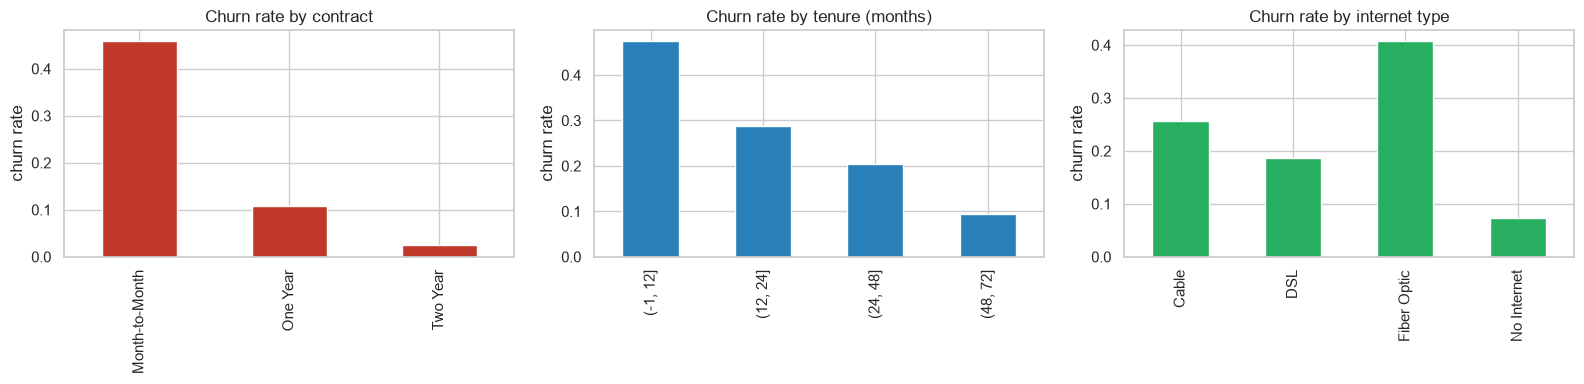

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.groupby('Contract')[TARGET].mean().plot.bar(ax=ax[0], color='#c0392b', title='Churn rate by contract')
df.assign(g=pd.cut(df['Tenure in Months'], [-1,12,24,48,72])).groupby('g', observed=True)[TARGET].mean().plot.bar(ax=ax[1], color='#2980b9', title='Churn rate by tenure (months)')
df.groupby('Internet Type')[TARGET].mean().plot.bar(ax=ax[2], color='#27ae60', title='Churn rate by internet type')
for a in ax: a.set_ylabel('churn rate'); a.set_xlabel('')
plt.tight_layout(); plt.savefig('../reports/eda.png', dpi=130); plt.show()

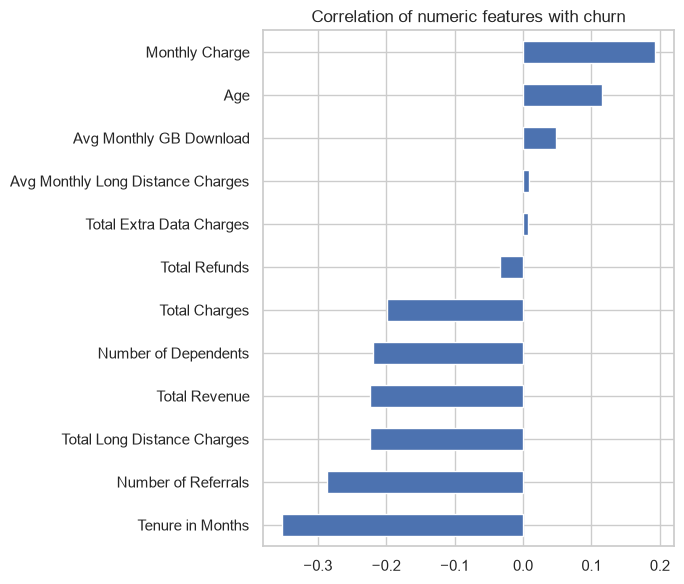

In [4]:
corr = df.select_dtypes('number').drop(columns=['Zip Code','Latitude','Longitude']).corr()[TARGET].drop(TARGET).sort_values()
corr.plot.barh(figsize=(7,6), title='Correlation of numeric features with churn'); plt.tight_layout(); plt.savefig('../reports/corr.png', dpi=130); plt.show()

The classes are imbalanced (about 26% churn), so metrics use ROC-AUC and PR-AUC rather than accuracy alone, and models use class weights.

## 3. Train / validation / test split
Done **before** any fitting or transformation (stratified 60/20/20). Imputation, scaling and encoding live inside the Pipeline, so they are fit on training folds only.

In [5]:
X = df.drop(columns=[TARGET]); y = df[TARGET]
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)
num, cat = split_columns(df)
print(len(X_train), len(X_val), len(X_test), '| features: %d numeric, %d categorical' % (len(num), len(cat)))

4225 1409 1409 | features: 12 numeric, 23 categorical


## 4. Compare models
Stratified 5-fold CV on the training set, then a check on the untouched validation set.

In [6]:
pos = (y_train == 0).sum() / (y_train == 1).sum()
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', n_jobs=-1, random_state=SEED),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, scale_pos_weight=pos, eval_metric='logloss', random_state=SEED, n_jobs=-1),
    'LightGBM': LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, class_weight='balanced', random_state=SEED, n_jobs=-1, verbose=-1),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for name, m in models.items():
    p = make_pipeline(m, num, cat)
    s = cross_val_score(p, X_train, y_train, cv=cv, scoring='roc_auc')
    p.fit(X_train, y_train); pr = p.predict_proba(X_val)[:, 1]
    rows.append({'model': name, 'cv_auc': s.mean(), 'cv_std': s.std(), 'val_auc': roc_auc_score(y_val, pr), 'val_pr_auc': average_precision_score(y_val, pr)})
results = pd.DataFrame(rows).set_index('model').round(4).sort_values('val_auc', ascending=False)
results

,cv_auc,cv_std,val_auc,val_pr_auc
model,,,,
XGBoost,0.9079,0.0011,0.9086,0.7995
LightGBM,0.8990,0.0027,0.9008,0.7803
Logistic Regression,0.9003,0.0067,0.8963,0.7719
Random Forest,0.8912,0.0044,0.8890,0.7569


## 5. Hyperparameter tuning
Randomized search (training set only) on the best tree model by validation AUC. Logistic regression stays as the reference baseline.

In [7]:
best_name = results.drop(index='Logistic Regression').index[0]
print('tuning:', best_name)
spaces = {
    'XGBoost': {'model__n_estimators': [150,300,500], 'model__max_depth': [2,3,4,5], 'model__learning_rate': [0.02,0.05,0.1], 'model__subsample': [0.7,0.85,1.0], 'model__colsample_bytree': [0.6,0.8,1.0]},
    'LightGBM': {'model__n_estimators': [150,300,500], 'model__num_leaves': [7,15,31], 'model__learning_rate': [0.02,0.05,0.1], 'model__subsample': [0.7,0.85,1.0], 'model__colsample_bytree': [0.6,0.8,1.0]},
    'Random Forest': {'model__n_estimators': [200,400], 'model__max_depth': [6,10,16,None], 'model__min_samples_leaf': [1,5,10,20]},
}
search = RandomizedSearchCV(make_pipeline(models[best_name], num, cat), spaces[best_name], n_iter=15, scoring='roc_auc', cv=cv, random_state=SEED)
search.fit(X_train, y_train)
print('best params:', search.best_params_); print('cv auc: %.4f' % search.best_score_)
tuned = search.best_estimator_
print('validation auc: %.4f' % roc_auc_score(y_val, tuned.predict_proba(X_val)[:, 1]))

tuning: XGBoost


best params: {'model__subsample': 1.0, 'model__n_estimators': 300, 'model__max_depth': 3, 'model__learning_rate': 0.05, 'model__colsample_bytree': 1.0}
cv auc: 0.9095
validation auc: 0.9078


## 6. Final evaluation (test set, used once)
The decision threshold is picked on the validation set (max F1 for churn). The model is then refit on train+validation and scored once on the held-out test set.

threshold from validation: 0.645


TEST ROC-AUC: 0.9128 | PR-AUC: 0.7862
              precision    recall  f1-score   support

      stayed       0.90      0.88      0.89      1035
     churned       0.69      0.74      0.72       374

    accuracy                           0.84      1409
   macro avg       0.80      0.81      0.80      1409
weighted avg       0.85      0.84      0.85      1409



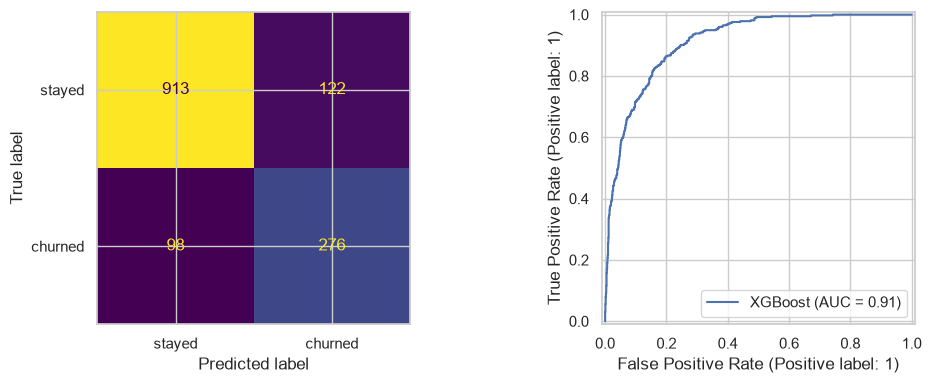

In [8]:
pv = tuned.predict_proba(X_val)[:, 1]
pr_, rc_, th_ = precision_recall_curve(y_val, pv); f1 = 2*pr_*rc_/(pr_+rc_+1e-12)
thr = float(th_[np.argmax(f1[:-1])]); print('threshold from validation: %.3f' % thr)
final = clone(tuned).fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))
pt = final.predict_proba(X_test)[:, 1]; yhat = (pt >= thr).astype(int)
print('TEST ROC-AUC: %.4f | PR-AUC: %.4f' % (roc_auc_score(y_test, pt), average_precision_score(y_test, pt)))
print(classification_report(y_test, yhat, target_names=['stayed','churned']))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, yhat, display_labels=['stayed','churned'], ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, pt, ax=ax[1], name=best_name)
plt.tight_layout(); plt.savefig('../reports/eval.png', dpi=130); plt.show()

## 7. What drives churn
Permutation importance on the test set, on the original columns (drop in AUC when a column is shuffled).

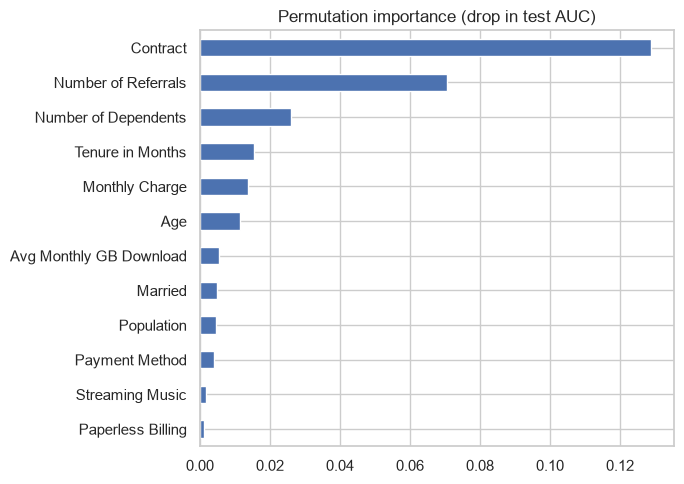

Contract                   0.1290
Number of Referrals        0.0705
Number of Dependents       0.0261
Tenure in Months           0.0155
Monthly Charge             0.0138
Age                        0.0114
Avg Monthly GB Download    0.0054
Married                    0.0048
dtype: float64

In [9]:
pi = permutation_importance(final, X_test, y_test, scoring='roc_auc', n_repeats=5, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
imp.head(12).iloc[::-1].plot.barh(figsize=(7,5), title='Permutation importance (drop in test AUC)')
plt.tight_layout(); plt.savefig('../reports/importance.png', dpi=130); plt.show()
imp.head(8).round(4)

## 8. Save the pipeline
The fitted `Pipeline` (preprocessing + model) and the chosen threshold are saved together, so scoring new data needs no manual preprocessing.

In [10]:
joblib.dump({'pipeline': final, 'threshold': thr, 'columns': num + cat, 'model': best_name}, '../models/best_model.pkl')
pd.Series({'model': best_name, 'test_roc_auc': roc_auc_score(y_test, pt), 'test_pr_auc': average_precision_score(y_test, pt), 'threshold': thr}).to_json('../reports/metrics.json', indent=2)
X_test.head(20).to_csv('../data/sample_customers.csv', index=False)
print(open('../reports/metrics.json').read())

{
  "model":"XGBoost",
  "test_roc_auc":0.9127580149,
  "test_pr_auc":0.7861609534,
  "threshold":0.6453989744
}


## 9. Conclusion and next steps
See the README for results, limitations and extensions.